In [1]:
import pandas as pd

path = '/content/PKKR71FL.DTA'
df = pd.read_stata(path, convert_categoricals=False)

print(df.shape)
df.head()

(12708, 1186)


,caseid,midx,v000,v001,v002,v003,v004,v005,v006,v007,...,sd005,idx94,s409a,s413aa,s413ab,s413ac,s437a,s443a,s451a,s469a
0,1 1 2,1,PK7,1,1,2,1,868683,2,2018,...,0.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
1,1 8 4,1,PK7,1,8,4,1,868683,2,2018,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1 8 7,1,PK7,1,8,7,1,868683,2,2018,...,NaN,1,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
3,1 9 4,1,PK7,1,9,4,1,868683,2,2018,...,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
4,1 9 4,2,PK7,1,9,4,1,868683,2,2018,...,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
df_lab = pd.read_stata(path)   # is baar labels (naam) ke saath
print(df_lab['v024'].value_counts())

v024
punjab         2759
sindh          2278
kpk            2097
balochistan    1508
ajk            1320
fata           1021
gb              915
ict             810
Name: count, dtype: int64


In [3]:
print(df['hw70'].notna().sum(), df['hw70'].isna().sum())
print(df['hw70'].describe())

4226 8482
count    4226.000000
mean       49.240416
std      1435.280426
min      -599.000000
25%      -258.000000
50%      -149.000000
75%       -44.000000
max      9998.000000
Name: hw70, dtype: float64


In [4]:
print((df['hw70'] >= 9990).sum())
print(df.loc[df['hw70'] >= 9990, 'hw70'].value_counts())

df_lab['measured'] = df['hw70'].notna()
print(df_lab.groupby('v024')['measured'].agg(['sum', 'count']))

85
hw70
9998.0    85
Name: count, dtype: int64
             sum  count
v024                   
punjab       906   2759
sindh        806   2278
kpk          702   2097
balochistan  513   1508
gb           278    915
ict          234    810
ajk          436   1320
fata         351   1021


/tmp/ipykernel_752/1471919167.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df_lab.groupby('v024')['measured'].agg(['sum', 'count']))


In [5]:
print(df['v007'].value_counts().sort_index())
print(df['v006'].value_counts().sort_index())

v007
2017    3723
2018    8985
Name: count, dtype: int64
v006
1     3898
2     3142
3     1685
4      260
11     375
12    3348
Name: count, dtype: int64


In [6]:
print(df_lab['hw13'].value_counts(dropna=False))

hw13
no measurement found in household    7490
measured                             4227
dead                                  719
not present                           111
refused                                86
other                                  72
NaN                                     3
Name: count, dtype: int64


In [7]:
print(df_lab.loc[df_lab['v024'] == 'sindh', 'hw13'].value_counts(dropna=False))

print(df.loc[(df['hw13'] == df_lab['hw13'].cat.categories[df_lab['hw13'].cat.categories.str.contains('measured') & ~df_lab['hw13'].cat.categories.str.contains('no')][0]) & df['hw70'].isna()].shape)

hw13
no measurement found in household    1308
measured                              806
dead                                  123
not present                            16
other                                  16
refused                                 8
NaN                                     1
Name: count, dtype: int64
(0, 1186)


In [8]:
m = df_lab['hw13'] == 'measured'
print((m & df_lab['hw70'].isna()).sum())
print((~m & df_lab['hw70'].notna()).sum())

2
1


In [9]:
print(df.shape)
print(df["hw13"].value_counts(dropna=False))

(12708, 1186)
hw13
7.0    7490
0.0    4227
1.0     719
3.0     111
4.0      86
6.0      72
NaN       3
Name: count, dtype: int64


In [10]:
print(((df['hw70'] == 9998) & m).sum())

85


In [11]:
# Define the "measured" flag again, in case it is not in memory
m = df_lab['hw13'] == 'measured'


In [13]:
# Are the 9998-flagged children counted as "measured"?
# Are the 9998-flagged children counted as "measured"?
print(((df['hw70'] == 9998) & m).sum())

85


In [14]:
# Sindh only: how many are flagged 9998, and how many scores are actually usable?
s = df[df['v024'] == 2]            # numeric code: 2 = Sindh
print((s['hw70'] == 9998).sum(), ((s['hw70'] < 9990) & s['hw70'].notna()).sum())

27 779


In [15]:
# DUPLICATES: siblings share a mother (caseid), so repeats are expected;
# the real test is whether any whole child row (caseid + midx) is repeated
print(df['caseid'].duplicated().sum())
print(df.duplicated(['caseid', 'midx']).sum())

4421
0


In [16]:
# UNITS: hw70 stores the z-score multiplied by 100 (e.g. -258 means -2.58),
# so after dividing by 100 the values should lie roughly between -6 and +6
ok = df.loc[df['hw70'] < 9990, 'hw70'] / 100
print(ok.describe())

count    4141.000000
mean       -1.549722
std         1.686982
min        -5.990000
25%        -2.620000
50%        -1.530000
75%        -0.510000
max         5.810000
Name: hw70, dtype: float64


In [17]:
# MISSING: do children with and without a height-for-age score differ
# in residence (v025), wealth (v190) and mother's education (v106)?
df['has_score'] = df['hw70'].notna()
print(df.groupby('has_score')[['v025', 'v190', 'v106']].agg(lambda x: x.mode()[0]))
print(df.groupby('has_score')['v025'].value_counts(normalize=True))


           v025  v190  v106
has_score                  
False         2     1     0
True          2     2     0
has_score  v025
False      2       0.565786
           1       0.434214
True       2       0.544250
           1       0.455750
Name: proportion, dtype: float64


/tmp/ipykernel_752/2045746531.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['has_score'] = df['hw70'].notna()


In [18]:
# ENCODING / WRONG TYPES: special codes stored as numbers
# (e.g. 98 = "don't know" in m14 is not a real number of visits)
print(df['m14'].value_counts().sort_index().tail())
print(df[['caseid', 'v113', 'v116']].dtypes)


m14
16.0     9
17.0     4
18.0     8
20.0    28
98.0    31
Name: count, dtype: int64
caseid    object
v113        int8
v116        int8
dtype: object


In [19]:
# DRIFT: stunting rate (z-score < -2) by interview year,
# using only valid scores (codes 9996-9998 excluded)
df['stunted'] = (df['hw70'] / 100 < -2)
print(df[df['hw70'] < 9990].groupby('v007')['stunted'].mean())

v007
2017    0.380282
2018    0.382030
Name: stunted, dtype: float64


/tmp/ipykernel_752/3360604652.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['stunted'] = (df['hw70'] / 100 < -2)


EDA ANALYSIS



In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PATH = '/content/PKKR71FL.DTA'          # change if your file is elsewhere
os.makedirs('figures', exist_ok=True)

df = pd.read_stata(PATH, convert_categoricals=False).copy()

# Cleaning (CLEANING.md entries 1-2): flagged codes >= 9990 -> missing; z-score is stored x100
df['haz'] = np.where(df['hw70'] < 9990, df['hw70'] / 100, np.nan)
df['stunted'] = np.where(df['haz'].notna(), (df['haz'] < -2).astype(float), np.nan)
df['w'] = df['v005'] / 1e6               # DHS weights carry 6 implied decimals

# Analysis sample: Sindh (v024 == 2) children with a valid height-for-age score
S = df[(df['v024'] == 2) & df['haz'].notna()].copy()
print('Sindh children in file:', (df['v024'] == 2).sum(), '| usable scores:', len(S))

def wrate(g):
    # weighted stunting rate and sample size for a group
    return pd.Series({'n': len(g), 'rate': np.average(g['stunted'], weights=g['w'])})

BLUE, RED, GREY = '#2a6f97', '#c0392b', '#8d99a6'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'figure.dpi': 110})

Sindh children in file: 2278 | usable scores: 779


Chart 1- Distribution

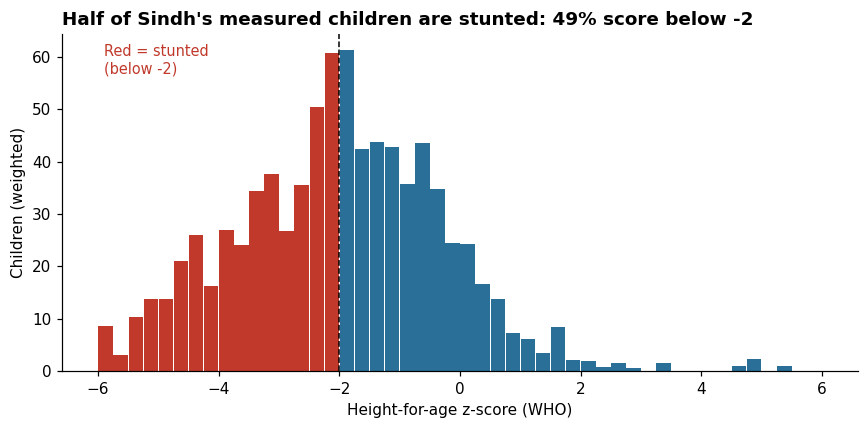

n = 779; weighted stunting = 0.493; unweighted = 0.465


In [23]:
overall = np.average(S['stunted'], weights=S['w'])
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(-6, 6.01, 0.25)
counts, edges = np.histogram(S['haz'], bins=bins, weights=S['w'])
centers = (edges[:-1] + edges[1:]) / 2
ax.bar(centers, counts, width=0.24, color=[RED if c < -2 else BLUE for c in centers])
ax.axvline(-2, color='black', lw=1, ls='--')
ax.text(-5.9, ax.get_ylim()[1] * 0.97, 'Red = stunted\n(below -2)', ha='left', va='top', color=RED, fontsize=9.5)
ax.set_xlabel('Height-for-age z-score (WHO)'); ax.set_ylabel('Children (weighted)')
ax.set_title(f"Half of Sindh's measured children are stunted: {overall:.0%} score below -2")
plt.tight_layout(); plt.savefig('figures/chart1_haz_distribution.png'); plt.show()
print(f'n = {len(S)}; weighted stunting = {overall:.3f}; unweighted = {S.stunted.mean():.3f}')

Chart 2-Age

/tmp/ipykernel_752/1131841863.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  age = S.groupby('age_group', observed=True).apply(wrate)


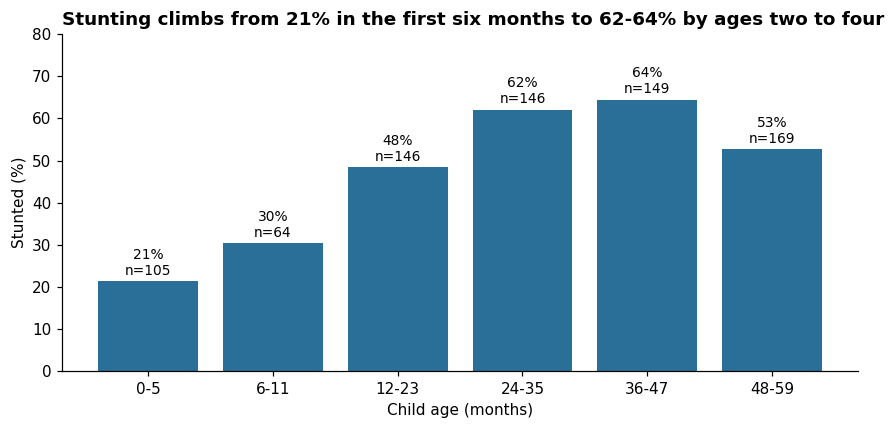

In [24]:
S['age_group'] = pd.cut(S['hw1'], [-1, 5, 11, 23, 35, 47, 59],
                        labels=['0-5', '6-11', '12-23', '24-35', '36-47', '48-59'])
age = S.groupby('age_group', observed=True).apply(wrate)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(age.index.astype(str), age['rate'] * 100, color=BLUE)
for i, (r, n) in enumerate(zip(age['rate'], age['n'])):
    ax.text(i, r * 100 + 1.5, f'{r:.0%}\nn={int(n)}', ha='center', fontsize=9)
ax.set_ylim(0, 80); ax.set_xlabel('Child age (months)'); ax.set_ylabel('Stunted (%)')
ax.set_title('Stunting climbs from 21% in the first six months to 62-64% by ages two to four')
plt.tight_layout(); plt.savefig('figures/chart2_age.png'); plt.show()

Chart 3- Wealth

/tmp/ipykernel_752/3972767017.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wealth = S.groupby('v190').apply(wrate)


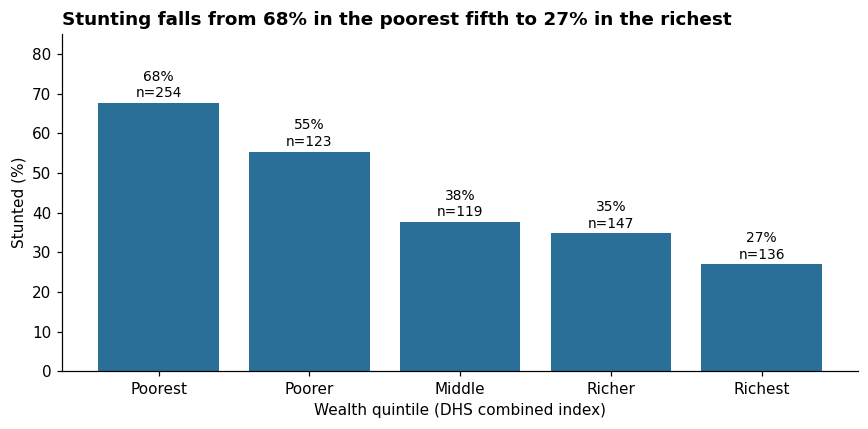

In [25]:
labels = {1: 'Poorest', 2: 'Poorer', 3: 'Middle', 4: 'Richer', 5: 'Richest'}
wealth = S.groupby('v190').apply(wrate)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([labels[i] for i in wealth.index], wealth['rate'] * 100, color=BLUE)
for i, (r, n) in enumerate(zip(wealth['rate'], wealth['n'])):
    ax.text(i, r * 100 + 1.5, f'{r:.0%}\nn={int(n)}', ha='center', fontsize=9)
ax.set_ylim(0, 85); ax.set_ylabel('Stunted (%)'); ax.set_xlabel('Wealth quintile (DHS combined index)')
ax.set_title('Stunting falls from 68% in the poorest fifth to 27% in the richest')
plt.tight_layout(); plt.savefig('figures/chart3_wealth.png'); plt.show()

Chart 4- cofounder check

/tmp/ipykernel_752/2804371594.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rural_urban = S.groupby('v025').apply(wrate)
/tmp/ipykernel_752/2804371594.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cells = S.groupby(['wealth_group', 'v025'], observed=True).apply(wrate).reset_index()


Overall urban (1) vs rural (2):
          n   rate
v025              
1     408.0  0.357
2     371.0  0.613
  wealth_group  v025      n   rate
0   Poor (1-2)     1   62.0  0.617
1   Poor (1-2)     2  315.0  0.641
2   Middle (3)     1   80.0  0.399
3   Middle (3)     2   39.0  0.334
4   Rich (4-5)     1  266.0  0.290
5   Rich (4-5)     2   17.0  0.592


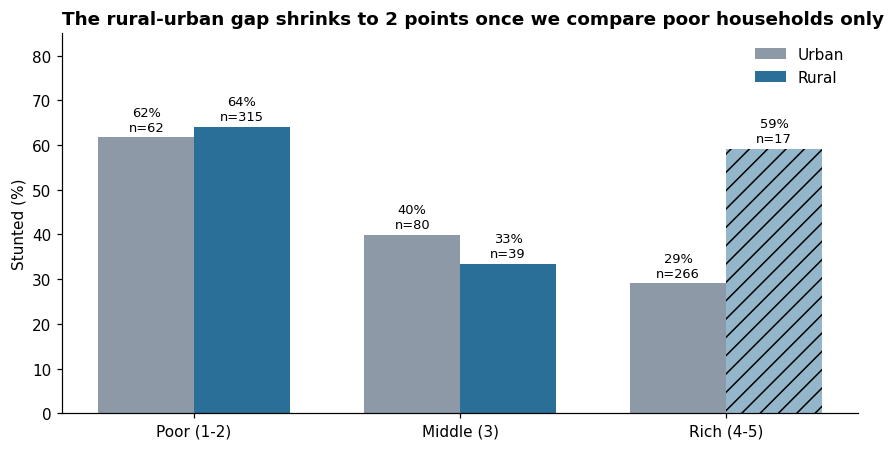

In [26]:
# Relationship: rural children are more stunted than urban. Third variable: household wealth.
rural_urban = S.groupby('v025').apply(wrate)
print('Overall urban (1) vs rural (2):'); print(rural_urban.round(3))

S['wealth_group'] = pd.cut(S['v190'], [0, 2, 3, 5], labels=['Poor (1-2)', 'Middle (3)', 'Rich (4-5)'])
cells = S.groupby(['wealth_group', 'v025'], observed=True).apply(wrate).reset_index()
print(cells.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
groups = ['Poor (1-2)', 'Middle (3)', 'Rich (4-5)']
x = np.arange(len(groups)); width = 0.36
for k, (code_, name, color) in enumerate([(1, 'Urban', GREY), (2, 'Rural', BLUE)]):
    sub = cells[cells['v025'] == code_].set_index('wealth_group').reindex(groups)
    bars = ax.bar(x + (k - 0.5) * width, sub['rate'] * 100, width, label=name, color=color)
    for b, r, n in zip(bars, sub['rate'], sub['n']):
        if n < 30:                          # hatch bars based on very few children
            b.set_hatch('//'); b.set_alpha(0.5)
        ax.text(b.get_x() + b.get_width() / 2, r * 100 + 1.5, f'{r:.0%}\nn={int(n)}', ha='center', fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(groups); ax.set_ylim(0, 85)
ax.set_ylabel('Stunted (%)'); ax.legend(frameon=False, loc='upper right')
ax.set_title('The rural-urban gap shrinks to 2 points once we compare poor households only')
plt.tight_layout(); plt.savefig('figures/chart4_confounder.png'); plt.show()

Chart 5- Transformation

n with a value: 575 | missing (first births): 204 | skew before: 2.06
skew after log: 0.2


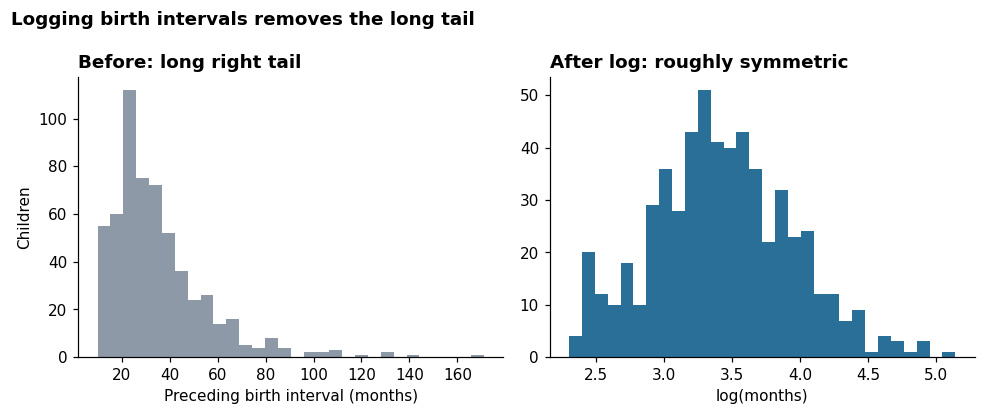

In [27]:
# b11 = months since the mother's previous birth; missing for first-born children
x = S['b11'].dropna()
print('n with a value:', len(x), '| missing (first births):', S['b11'].isna().sum(), '| skew before:', round(x.skew(), 2))
logx = np.log(x)
print('skew after log:', round(logx.skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].hist(x, bins=30, color=GREY); axes[0].set_title('Before: long right tail')
axes[0].set_xlabel('Preceding birth interval (months)'); axes[0].set_ylabel('Children')
axes[1].hist(logx, bins=30, color=BLUE); axes[1].set_title('After log: roughly symmetric')
axes[1].set_xlabel('log(months)')
fig.suptitle('Logging birth intervals removes the long tail', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/chart5_log_transform.png'); plt.show()